# Neural Network (PyTorch) - Concentration

In [1]:
import os
os.environ['KMP_DUPLICATE_LIB_OK'] = 'TRUE'
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['MKL_NUM_THREADS'] = '1'

import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

from scipy.stats import pearsonr
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

import torch
torch.set_num_threads(1)
import torch.nn as nn

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {DEVICE}")

# ── Shared repo locations (sf_statistics/src/utils/paths.py) ─────────────────
import sys
from pathlib import Path
_here = Path.cwd().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents]
                 if (p / 'sf_statistics' / 'src' / 'utils' / 'paths.py').exists())
sys.path.insert(0, str(REPO_ROOT / 'sf_statistics'))
from src.utils.paths import ML_DATA_CSV, ML_IMPORTANCES_DIR

Using device: cpu


In [2]:
## ── CONFIGURATION ──
# This will be the section I can edit to change the model
# All subsequent cells read from CONFIG

CONFIG = {
    # Target metric: 'G', 'C', 'A', or 'S'
    'target': 'C',

    # Restrict to the full purity/quality-cut sample (in_full_sam == True)?
    'require_full_sam': True,

    # Spectral class sample: 'pure_SF', 'composite_SF', or 'both'
    'spectral_sample': 'both',

    # Model A or B
    # False = Model A (primary):     no halo mass, full spectral sample
    # True  = Model B (sensitivity): adds log_MassA_1, restricted to non-null halo mass
    'halo_mass': False,

    # Include closest companion distance as a predictor?
    'include_companion': False,

    # Include cosmic web distances as predictors?
    # Dfil/Dnode/Dvoid are field-only (NaN for all Cluster galaxies); enabling
    # any of these restricts the sample to GAMA field galaxies (via dropna below).
    'include_Dfil':  False,
    'include_Dnode': False,
    'include_Dvoid': False,

    # Subgroup: 'all', 'field' (environment=0), or 'cluster' (environment=1)
    'subgroup': 'all',

    # Seeing cut: None for no cut, or a float e.g. 0.1
    'seeing_cut': None,

    # ── CV and reproducibility 
    'n_folds':     5,
    'random_seed': 42,

    # ── Permutation importance 
    'perm_n_repeats': 10,

    # ── NN architecture 
    'hidden_layers': (64, 32),   # two hidden layers; kept small on purpose (N~700)
    'dropout':       0.3,

    # ── NN training 
    'learning_rate':          1e-3,
    'weight_decay':           1e-4,   
    'batch_size':              32,
    'max_epochs':              300,
    'early_stopping_patience': 20,    # epochs of no val-loss improvement
    'val_split':               0.15, # fraction of EACH training fold held out for early stopping

    # ── I/O ────────────────────────────────────────────────────────────────
    'data_path':  ML_DATA_CSV,
}

BASE_FEATURES = [
    'log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated',
    'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms'
]

FEATURES = BASE_FEATURES.copy()
if CONFIG['include_companion']:
    FEATURES.append('closest_companion_kpc')
if CONFIG['halo_mass']:
    FEATURES.append('log_MassA_1')
if CONFIG['include_Dfil']:
    FEATURES.append('Dfil')
if CONFIG['include_Dnode']:
    FEATURES.append('Dnode')
if CONFIG['include_Dvoid']:
    FEATURES.append('Dvoid')
# NOTE: spectral_class is intentionally NOT added to FEATURES here, matching
# the RF script's actual (as-run) behaviour -- it is used to filter the
# sample (below) but does not enter X. Kept identical for a fair comparison;
# revisit if you decide to fix this in the RF script too.

model_variant = 'B' if CONFIG['halo_mass'] else 'A'
RUN_LABEL = f"NN_Model{model_variant}_{CONFIG['target']}_{CONFIG['spectral_sample']}_{CONFIG['subgroup']}"
if not CONFIG['include_companion']:
    RUN_LABEL += '_nocompanion'
cosmic_web_flags = [name for name, flag in
                     [('Dfil', CONFIG['include_Dfil']),
                      ('Dnode', CONFIG['include_Dnode']),
                      ('Dvoid', CONFIG['include_Dvoid'])] if flag]
if cosmic_web_flags:
    RUN_LABEL += '_' + '-'.join(cosmic_web_flags)
if CONFIG['seeing_cut'] is not None:
    RUN_LABEL += f"_seeinglt{CONFIG['seeing_cut']}"

print(f"Run label        : {RUN_LABEL}")
print(f"Target           : {CONFIG['target']}")
print(f"Cosmic web       : Dfil={CONFIG['include_Dfil']}, Dnode={CONFIG['include_Dnode']}, Dvoid={CONFIG['include_Dvoid']}"
      + (" (restricts sample to GAMA field galaxies)" if cosmic_web_flags else ""))
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

Run label        : NN_ModelA_C_both_all_nocompanion
Target           : C
Cosmic web       : Dfil=False, Dnode=False, Dvoid=False
Base features (11): ['log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated', 'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms']


## Load Data & Applying Filters

In [3]:
df_raw = pd.read_csv(CONFIG['data_path'])
target = CONFIG['target']

df = df_raw.copy()

# Keep only galaxies with a valid target measurement
valid_target = np.isfinite(df[target]) & (df[target] != -999)
df = df[valid_target]

# Restrict to the full purity/quality-cut sample
if CONFIG['require_full_sam']:
    df = df[df['in_full_sam'] == True]

# Spectral class filter
if CONFIG['spectral_sample'] == 'pure_SF':
    df = df[df['spectral_class'] == 'pure_SF']
elif CONFIG['spectral_sample'] == 'composite_SF':
    df = df[df['spectral_class'] == 'composite_SF']

# Optional subgroup filter
if CONFIG['subgroup'] == 'field':
    df = df[df['environment'] == 'GAMA']
elif CONFIG['subgroup'] == 'cluster':
    df = df[df['environment'] == 'Cluster']

# Optional seeing cut
if CONFIG['seeing_cut'] is not None:
    df = df[df['seeing'] <= CONFIG['seeing_cut']]

# Model B -- restrict to galaxies with halo mass
if CONFIG['halo_mass']:
    df = df.dropna(subset=['log_MassA_1'])

# spectral_class kept in the dropna filter only, to match the RF sample exactly
feature_cols = FEATURES.copy()
if CONFIG['spectral_sample'] == 'both':
    feature_cols.append('spectral_class')

df = df.dropna(subset=feature_cols)
print(f"N galaxies after filtering: {len(df)}")
df.head()

N galaxies after filtering: 704


,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,5NN_err,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster
2,7206,0.050523,0.319035,0.262159,0.175119,composite_SF,GAMA,3.33,5.852094,2.221746,...,0.0143,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False
10,8319,-0.012790,NaN,0.253771,0.977369,pure_SF,GAMA,11.72,1.542886,4.256585,...,0.1714,True,-0.604389,NaN,NaN,NaN,False,False,True,False
11,8353,0.040326,0.382265,0.629758,0.214762,pure_SF,GAMA,5.37,2.332199,1.989649,...,0.0261,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False
19,8570,-0.071971,0.317977,0.280710,0.406769,pure_SF,GAMA,4.80,2.169676,2.852864,...,0.5597,True,-0.498352,NaN,NaN,NaN,False,True,False,False
20,8703,0.022114,0.399060,0.149497,0.306544,composite_SF,GAMA,8.39,3.752812,3.352634,...,0.1362,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False


In [4]:
# Add RANDOM baseline feature (drawn fresh every run -- never saved to CSV)
# Any feature with importance <= RANDOM is non-informative
rng = np.random.default_rng(CONFIG['random_seed'])
df['RANDOM'] = rng.uniform(0, 1, len(df))
FEATURES.append('RANDOM')

In [5]:
# Build X and y
X = df[FEATURES].values.astype(np.float32)
y = df[target].values.astype(np.float32)
feature_names = FEATURES
stratify_labels = df['environment'].values

print(f"Final sample     : {len(y):,} galaxies")
print(f"Features ({len(feature_names):>2})    : {feature_names}")
print(f"Target range, {target}: {y.min():.4f}  to  {y.max():.4f}  (mean={y.mean():.4f})")

Final sample     : 704 galaxies
Features (12)    : ['log_Mstar', 'log_sSFR', '5NN', 'is_satellite', 'is_isolated', 'is_central', 'is_cluster', 'ellip', 'z', 're', 'delta_ms', 'RANDOM']
Target range, C: -0.5444  to  0.2857  (mean=-0.0520)


In [6]:
df

,CATID,C,G,A,S,spectral_class,environment,re,re_kpc,n_res,...,in_full_sam,delta_ms,Dfil,Dnode,Dvoid,is_satellite,is_central,is_isolated,is_cluster,RANDOM
2,7206,0.050523,0.319035,0.262159,0.175119,composite_SF,GAMA,3.33,5.852094,2.221746,...,True,0.511836,0.847793,5.237409,11.880854,False,True,False,False,0.773956
10,8319,-0.012790,NaN,0.253771,0.977369,pure_SF,GAMA,11.72,1.542886,4.256585,...,True,-0.604389,NaN,NaN,NaN,False,False,True,False,0.438878
11,8353,0.040326,0.382265,0.629758,0.214762,pure_SF,GAMA,5.37,2.332199,1.989649,...,True,0.312850,1.395220,2.242314,8.374062,False,False,True,False,0.858598
19,8570,-0.071971,0.317977,0.280710,0.406769,pure_SF,GAMA,4.80,2.169676,2.852864,...,True,-0.498352,NaN,NaN,NaN,False,True,False,False,0.697368
20,8703,0.022114,0.399060,0.149497,0.306544,composite_SF,GAMA,8.39,3.752812,3.352634,...,True,0.109155,1.343619,1.862234,6.000984,False,True,False,False,0.094177
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2469,9016800065,-0.103140,0.505760,0.144198,0.127332,composite_SF,Cluster,3.11,3.010246,1.462560,...,True,-0.295411,NaN,NaN,NaN,False,False,False,True,0.299383
2473,9016800074,-0.346120,0.697836,0.156563,0.271170,composite_SF,Cluster,4.79,4.308533,2.252624,...,True,-0.321439,NaN,NaN,NaN,False,False,False,True,0.241372
2480,9016800093,0.029210,0.240138,0.348957,0.287012,composite_SF,Cluster,7.15,6.348893,3.374540,...,True,-0.031702,NaN,NaN,NaN,False,False,False,True,0.322492
2482,9016800095,-0.238280,0.603134,0.219906,0.224573,pure_SF,Cluster,4.61,4.158615,2.352938,...,True,0.201943,NaN,NaN,NaN,False,False,False,True,0.155442


## Neural Network architecture

The network is kept deliberately small (two hidden layers, dropout 0.3, weight decay) given the sample size (~700 galaxies, ~560 per training fold): a larger network here would memorise noise rather than learn signal.

In [7]:
class TabularNet(nn.Module):
    def __init__(self, n_features, hidden_layers=(64, 32), dropout=0.3):
        super().__init__()
        layers = []
        in_dim = n_features
        for h in hidden_layers:
            layers += [nn.Linear(in_dim, h), nn.BatchNorm1d(h), nn.ReLU(), nn.Dropout(dropout)]
            in_dim = h
        layers.append(nn.Linear(in_dim, 1))
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x).squeeze(-1)

## Sklearn-compatible wrapper

Wraps the PyTorch train/scale/early-stop routine behind `.fit(X, y)` / `.predict(X)` so it drops straight into `sklearn.inspection.permutation_importance` and keeps the CV loop below structurally identical to the RF script.

Key points:
- The scaler is fit **only on the training fold** (refit inside every `.fit()` call), matching the same leakage discipline the RF's permutation importance already respects for the test fold.
- An **inner validation split** is carved out of the training fold purely for early stopping -- the outer test fold is never touched until `.predict()`.
- Early stopping restores the **best-val-loss weights**, not whatever the model looked like when training happened to stop.

In [8]:
class TorchMLPRegressor(BaseEstimator, RegressorMixin):
    def __init__(self, n_features=None, hidden_layers=(64, 32), dropout=0.3,
                 lr=1e-3, weight_decay=1e-4, batch_size=32, max_epochs=300,
                 patience=20, val_split=0.15, random_state=42, device='cpu'):
        self.n_features = n_features
        self.hidden_layers = hidden_layers
        self.dropout = dropout
        self.lr = lr
        self.weight_decay = weight_decay
        self.batch_size = batch_size
        self.max_epochs = max_epochs
        self.patience = patience
        self.val_split = val_split
        self.random_state = random_state
        self.device = device

    def fit(self, X, y):
        torch.manual_seed(self.random_state)
        np.random.seed(self.random_state)

        # Inner split: held out ONLY for early stopping, never used in weight updates
        X_tr, X_val, y_tr, y_val = train_test_split(
            X, y, test_size=self.val_split, random_state=self.random_state
        )

        # Scale on the inner-training data only
        self.scaler_ = StandardScaler().fit(X_tr)
        X_tr_s  = self.scaler_.transform(X_tr)
        X_val_s = self.scaler_.transform(X_val)

        Xtr_t  = torch.tensor(X_tr_s,  dtype=torch.float32, device=self.device)
        ytr_t  = torch.tensor(y_tr,    dtype=torch.float32, device=self.device)
        Xval_t = torch.tensor(X_val_s, dtype=torch.float32, device=self.device)
        yval_t = torch.tensor(y_val,   dtype=torch.float32, device=self.device)

        n_features = X.shape[1] if self.n_features is None else self.n_features
        self.model_ = TabularNet(n_features, self.hidden_layers, self.dropout).to(self.device)
        optimizer = torch.optim.Adam(self.model_.parameters(), lr=self.lr, weight_decay=self.weight_decay)
        loss_fn = nn.MSELoss()

        best_val_loss = np.inf
        best_state = copy.deepcopy(self.model_.state_dict())
        epochs_no_improve = 0
        self.best_epoch_ = 0

        n_train = Xtr_t.shape[0]
        for epoch in range(self.max_epochs):
            self.model_.train()
            perm = torch.randperm(n_train)
            for i in range(0, n_train, self.batch_size):
                idx = perm[i:i + self.batch_size]
                optimizer.zero_grad()
                pred = self.model_(Xtr_t[idx])
                loss = loss_fn(pred, ytr_t[idx])
                loss.backward()
                optimizer.step()

            self.model_.eval()
            with torch.no_grad():
                val_pred = self.model_(Xval_t)
                val_loss = loss_fn(val_pred, yval_t).item()

            if val_loss < best_val_loss - 1e-6:
                best_val_loss = val_loss
                best_state = copy.deepcopy(self.model_.state_dict())
                self.best_epoch_ = epoch
                epochs_no_improve = 0
            else:
                epochs_no_improve += 1
                if epochs_no_improve >= self.patience:
                    break

        self.model_.load_state_dict(best_state)
        self.model_.eval()
        self.stopped_epoch_ = epoch
        self.best_val_loss_ = best_val_loss
        return self

    def predict(self, X):
        X_s = self.scaler_.transform(X)
        X_t = torch.tensor(X_s, dtype=torch.float32, device=self.device)
        with torch.no_grad():
            preds = self.model_(X_t).cpu().numpy()
        return preds

## 5-Fold Stratified Cross Validation Loop

Same `StratifiedKFold` (stratified on `environment`), same fold indices logic, same `random_seed` as the RF script -- this is what makes the two directly comparable. There is no OOB score (no bagging in a NN) and no MDI (dropped, per discussion); a `best_epoch` diagnostic is printed instead, to sanity-check that early stopping isn't triggering suspiciously early or never triggering at all.

In [9]:
# ── Initialise storage ──────────────────────────────────────────────────────────────────
fold_r2, fold_rmse, fold_mae = [], [], []
perm_importances = []
oof_true = np.zeros(len(y))
oof_pred = np.zeros(len(y))

# ── Cross Validation splitter (stratified on environment) ─────────────────
skf = StratifiedKFold(
    n_splits=CONFIG['n_folds'],
    shuffle=True,
    random_state=CONFIG['random_seed'],
)

def build_nn(n_features, seed_offset=0):
    return TorchMLPRegressor(
        n_features=n_features,
        hidden_layers=CONFIG['hidden_layers'],
        dropout=CONFIG['dropout'],
        lr=CONFIG['learning_rate'],
        weight_decay=CONFIG['weight_decay'],
        batch_size=CONFIG['batch_size'],
        max_epochs=CONFIG['max_epochs'],
        patience=CONFIG['early_stopping_patience'],
        val_split=CONFIG['val_split'],
        random_state=CONFIG['random_seed'] + seed_offset,
        device=DEVICE,
    )

# ── Main CV loop ──────────────────────────────────────────────────────────
print(f"Running {CONFIG['n_folds']}-fold stratified CV  --  {RUN_LABEL}")
print(f"{'Fold':>5}  {'N_train':>8}  {'N_test':>7}  {'R2':>8}  {'RMSE':>8}  {'MAE':>8}  {'BestEp':>7}")
print("-" * 65)

for fold_idx, (train_idx, test_idx) in enumerate(skf.split(X, stratify_labels)):

    X_train, X_test = X[train_idx], X[test_idx]
    y_train, y_test = y[train_idx], y[test_idx]

    nn_model = build_nn(n_features=X.shape[1], seed_offset=fold_idx)
    nn_model.fit(X_train, y_train)
    y_pred = nn_model.predict(X_test)

    oof_true[test_idx] = y_test
    oof_pred[test_idx] = y_pred

    r2   = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))
    mae  = mean_absolute_error(y_test, y_pred)

    fold_r2.append(r2); fold_rmse.append(rmse); fold_mae.append(mae)

    # Permutation importance (out-of-sample, on held-out fold) -- PRIMARY (and only) measure
    perm_result = permutation_importance(
        nn_model, X_test, y_test,
        n_repeats   = CONFIG['perm_n_repeats'],
        random_state= CONFIG['random_seed'] + fold_idx,
        scoring     = 'r2',
    )
    perm_importances.append(perm_result.importances_mean)

    print(f"{fold_idx+1:>5}  {len(y_train):>8,}  {len(y_test):>7,}  {r2:>8.4f}  {rmse:>8.4f}  {mae:>8.4f}  {nn_model.best_epoch_:>7}")

print("-" * 65)
print(f"{'Mean':>5}  {'':>8}  {'':>7}  {np.mean(fold_r2):>8.4f}  {np.mean(fold_rmse):>8.4f}  {np.mean(fold_mae):>8.4f}")
print(f"{'Std':>5}  {'':>8}  {'':>7}  {np.std(fold_r2):>8.4f}  {np.std(fold_rmse):>8.4f}  {np.std(fold_mae):>8.4f}")

Running 5-fold stratified CV  --  NN_ModelA_C_both_all_nocompanion
 Fold   N_train   N_test        R2      RMSE       MAE   BestEp
-----------------------------------------------------------------
    1       563      141   -0.0166    0.1240    0.0936      117
    2       563      141   -0.0736    0.1199    0.0848       55
    3       563      141    0.1713    0.1005    0.0764       63
    4       563      141    0.1064    0.0930    0.0715       28
    5       564      140    0.1118    0.1245    0.0920       14
-----------------------------------------------------------------
 Mean                       0.0599    0.1124    0.0837
  Std                       0.0905    0.0131    0.0086


## Performance Summary and Predicted vs Actual Plot

Identical to the RF script -- built entirely from `oof_true`/`oof_pred`, so it carries over unchanged regardless of what generated the predictions.

=== Performance Summary  --  NN_ModelA_C_both_all_nocompanion ===
Metric   Mean    Std     Min    Max
    R2 0.0599 0.0905 -0.0736 0.1713
  RMSE 0.1124 0.0131  0.0930 0.1245
   MAE 0.0837 0.0086  0.0715 0.0936


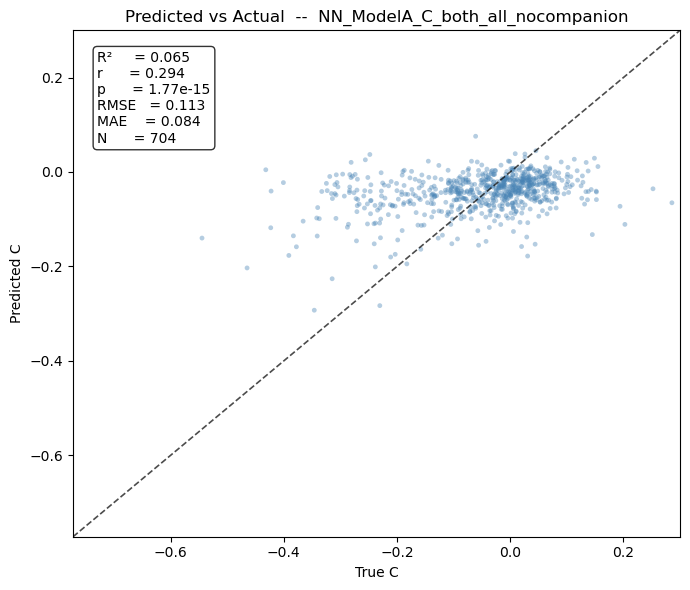

In [10]:
# Performance summary table
perf_df = pd.DataFrame({
    'Metric': ['R2', 'RMSE', 'MAE'],
    'Mean':   [np.mean(fold_r2),   np.mean(fold_rmse),   np.mean(fold_mae)],
    'Std':    [np.std(fold_r2),    np.std(fold_rmse),    np.std(fold_mae)],
    'Min':    [np.min(fold_r2),    np.min(fold_rmse),    np.min(fold_mae)],
    'Max':    [np.max(fold_r2),    np.max(fold_rmse),    np.max(fold_mae)],
})
print(f"=== Performance Summary  --  {RUN_LABEL} ===")
print(perf_df.to_string(index=False, float_format='{:.4f}'.format))
# perf_df.to_csv(os.path.join(CONFIG['output_dir'], f'{RUN_LABEL}_performance.csv'), index=False)

# Predicted vs Actual scatter (out-of-fold -- full sample, no leakage)
overall_r2   = r2_score(oof_true, oof_pred)
overall_rmse = np.sqrt(mean_squared_error(oof_true, oof_pred))
overall_mae  = mean_absolute_error(oof_true, oof_pred)

r_pearson, p_pearson = pearsonr(oof_true, oof_pred)

fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(oof_true, oof_pred, s=12, alpha=0.4, color='steelblue',
           edgecolors='none', rasterized=True)
lims = [min(oof_true.min(), oof_pred.min()) * 0.95,
        max(oof_true.max(), oof_pred.max()) * 1.05]
ax.plot(lims, lims, 'k--', linewidth=1.2, alpha=0.7)
ax.set_xlim(lims); ax.set_ylim(lims)
textstr = (f'R²     = {overall_r2:.3f}\n'
           f'r      = {r_pearson:.3f}\n'
           f'p      = {p_pearson:.2e}\n'
           f'RMSE   = {overall_rmse:.3f}\n'
           f'MAE    = {overall_mae:.3f}\n'
           f'N      = {len(oof_true):,}')
ax.text(0.04, 0.96, textstr, transform=ax.transAxes, fontsize=10,
        verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
ax.set_xlabel(f'True {target}'); ax.set_ylabel(f'Predicted {target}')
ax.set_title(f'Predicted vs Actual  --  {RUN_LABEL}')
plt.tight_layout()
plt.show()

In [11]:
# Save performance summary for the thesis figure (importances/ folder)
IMPORTANCES_DIR = ML_IMPORTANCES_DIR
os.makedirs(IMPORTANCES_DIR, exist_ok=True)
perf_out_path = os.path.join(IMPORTANCES_DIR, f'NN_{target}_performance.csv')
perf_df.to_csv(perf_out_path, index=False)
print(f"Saved {perf_out_path}")

Saved /Users/sophiesinclair/Desktop/sami copy/outputs/ch4/importances/NN_C_performance.csv


## Feature Importance: Permutation

Permutation-only, matching the earlier decision -- no MDI equivalent exists for a NN. Same `FEATURE_COLOURS` map and `importance_bar_chart` helper as the RF script, so figures stay visually consistent across the two notebooks.

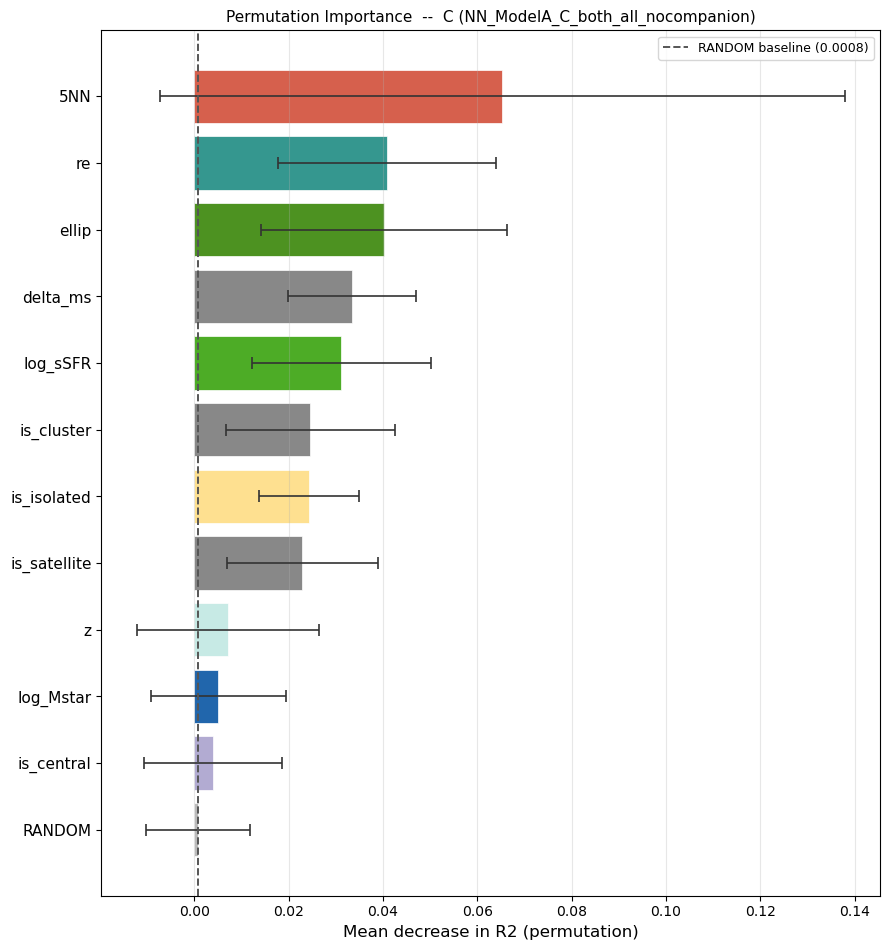

In [12]:
# Aggregate importances across folds
perm_array = np.array(perm_importances)

perm_df = pd.DataFrame({
    'Feature': feature_names, 'Perm_Mean': perm_array.mean(axis=0),
    'Perm_Std': perm_array.std(axis=0),
}).sort_values('Perm_Mean', ascending=False).reset_index(drop=True)

random_perm = perm_df.loc[perm_df['Feature'] == 'RANDOM', 'Perm_Mean'].values[0]

# Feature colour map -- kept identical to RF_G.ipynb; add new features, keep existing colours consistent
FEATURE_COLOURS = {
    'log_Mstar':              '#2166AC',  # dark blue   -- stellar mass
    'log_sSFR':               '#4DAC26',  # green       -- SF activity
    '5NN':                    '#D6604D',  # red         -- local density
    'environment':            '#F4A582',  # light red   -- broad environment
    'is_isolated':            '#FEE090',  # yellow      -- isolation
    'closest_companion_kpc':  '#92C5DE',  # light blue  -- interaction distance
    'log_MassA_1':            '#762A83',  # purple      -- halo mass (Model B)
    'is_central':             '#B2ABD2',  # lavender    -- central/satellite
    'ellip':                  '#4D9221',  # dark green  -- structural
    'z':                      '#C7EAE5',  # pale teal   -- redshift
    're':                     '#35978F',  # teal        -- galaxy size
    'spectral_class':         '#E08214',  # orange      -- SF class (both only)
    'Dfil':                   '#A6761D',  # brown/gold  -- distance to filament
    'Dnode':                  '#E7298A',  # magenta     -- distance to node
    'Dvoid':                  '#666666',  # dark grey   -- distance to void
    'RANDOM':                 '#BBBBBB',  # grey        -- noise baseline
}

def importance_bar_chart(df_imp, mean_col, std_col, random_val, title, xlabel, filename):
    n = len(df_imp)
    fig, ax = plt.subplots(figsize=(9, 0.65 * n + 1.8))
    features = df_imp['Feature'].tolist()
    means, stds = df_imp[mean_col].values, df_imp[std_col].values
    colours = [FEATURE_COLOURS.get(f, '#888888') for f in features]
    y_pos = np.arange(n)[::-1]
    ax.barh(y_pos, means, xerr=stds, capsize=4, color=colours,
            edgecolor='white', linewidth=0.5,
            error_kw={'elinewidth': 1.2, 'ecolor': '#333333', 'capthick': 1.2})
    ax.axvline(random_val, color='#555555', linestyle='--', linewidth=1.4,
               label=f'RANDOM baseline ({random_val:.4f})')
    ax.set_yticks(y_pos); ax.set_yticklabels(features, fontsize=11)
    ax.set_xlabel(xlabel, fontsize=12); ax.set_title(title, fontsize=11)
    ax.legend(fontsize=9); ax.grid(axis='x', alpha=0.3)
    plt.tight_layout()
    plt.show()

importance_bar_chart(perm_df, 'Perm_Mean', 'Perm_Std', random_perm,
    title=f'Permutation Importance  --  {target} ({RUN_LABEL})',
    xlabel='Mean decrease in R2 (permutation)',
    filename=f'{RUN_LABEL}_perm_importance.png')

In [13]:
# Save importance numbers for the thesis figure (importances/ folder)
IMPORTANCES_DIR = ML_IMPORTANCES_DIR
os.makedirs(IMPORTANCES_DIR, exist_ok=True)
imp_out_path = os.path.join(IMPORTANCES_DIR, f'NN_{target}.csv')
perm_df.to_csv(imp_out_path, index=False)
print(f"Saved {imp_out_path}")

Saved /Users/sophiesinclair/Desktop/sami copy/outputs/ch4/importances/NN_C.csv


## Feature Relationship Explorer

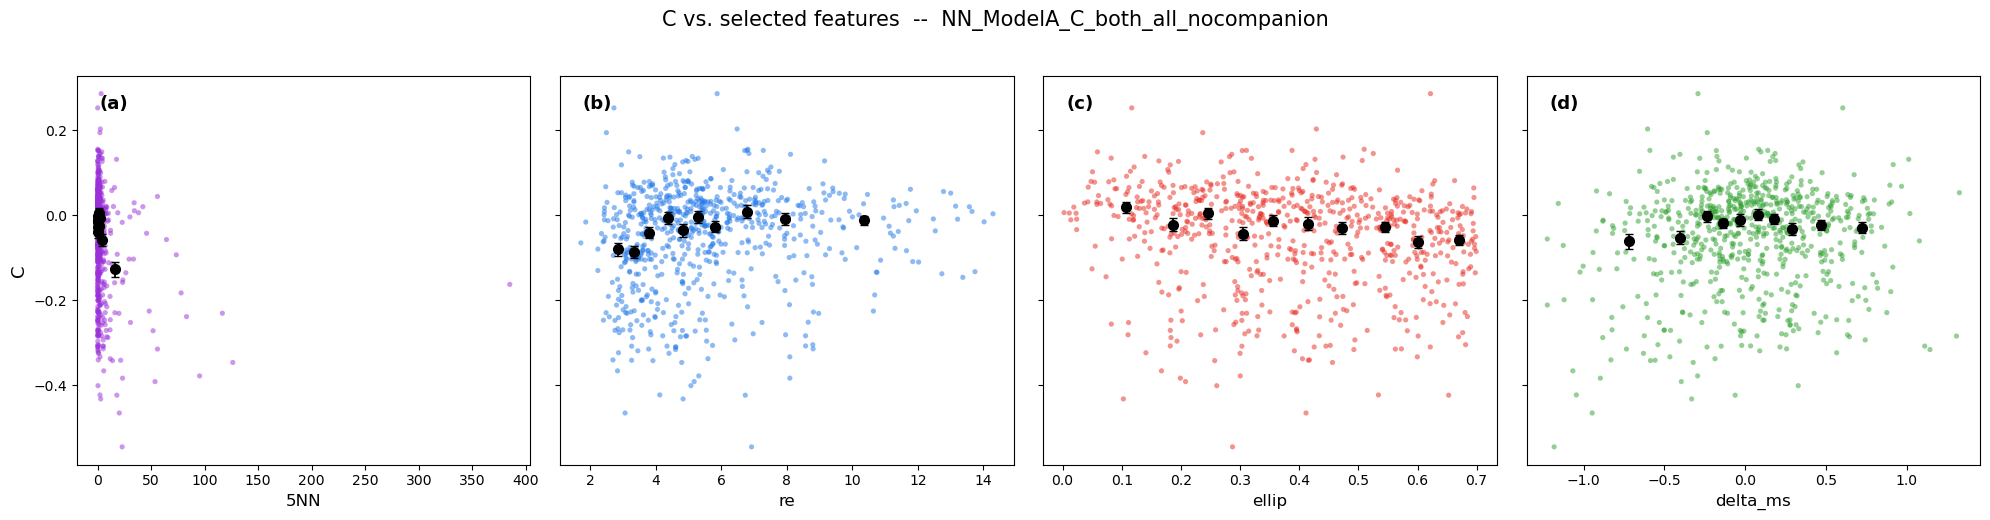

In [14]:
FEATURES_TO_PLOT = ['5NN', 're', 'ellip', 'delta_ms']  

N_BINS = 10
PANEL_COLOURS = ['#9B30D9', '#1F77E8', '#E8291F', '#2CA02C']  
PANEL_LETTERS = ['(a)', '(b)', '(c)', '(d)']

assert len(FEATURES_TO_PLOT) == 4, "Pick exactly 4 features for the 1x4 row"
for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling against FEATURES"

fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
    colour = PANEL_COLOURS[i]
    is_binary = df[feat].nunique() <= 2
    n_points = df[[feat, target]].dropna().shape[0]

    if is_binary:
        sns.boxplot(
            data=df, x=feat, y=target, ax=ax,
            color=colour, width=0.5, fliersize=2,
            boxprops=dict(alpha=0.75), medianprops=dict(color='black', linewidth=1.5),
        )

    else:
        x = df[feat].values
        y = df[target].values

        ax.scatter(x, y, s=14, alpha=0.5, color=colour, edgecolors='none', rasterized=True)

        # Binned medians (black points, error bars only — no connecting line)
        bin_edges = np.nanquantile(x, np.linspace(0, 1, N_BINS + 1))
        bin_edges = np.unique(bin_edges)
        bin_idx = np.digitize(x, bin_edges[1:-1])

        bin_x, bin_y, bin_yerr = [], [], []
        for b in range(len(bin_edges) - 1):
            mask = bin_idx == b
            if mask.sum() < 3:
                continue
            bin_x.append(np.median(x[mask]))
            bin_y.append(np.median(y[mask]))
            bin_yerr.append(np.std(y[mask]) / np.sqrt(mask.sum()))

        ax.errorbar(bin_x, bin_y, yerr=bin_yerr, fmt='o', color='black',
                     markerfacecolor='black', markersize=7, linewidth=1.3,
                     capsize=3, zorder=5)


    # Panel letter, top-left
    ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
            fontsize=13, fontweight='bold', va='top', ha='left')

    ax.set_xlabel(feat, fontsize=12)
    if i == 0:
        ax.set_ylabel(target, fontsize=13)

fig.suptitle(f'{target} vs. selected features  --  {RUN_LABEL}', fontsize=15, y=1.03)
plt.tight_layout()
plt.show()

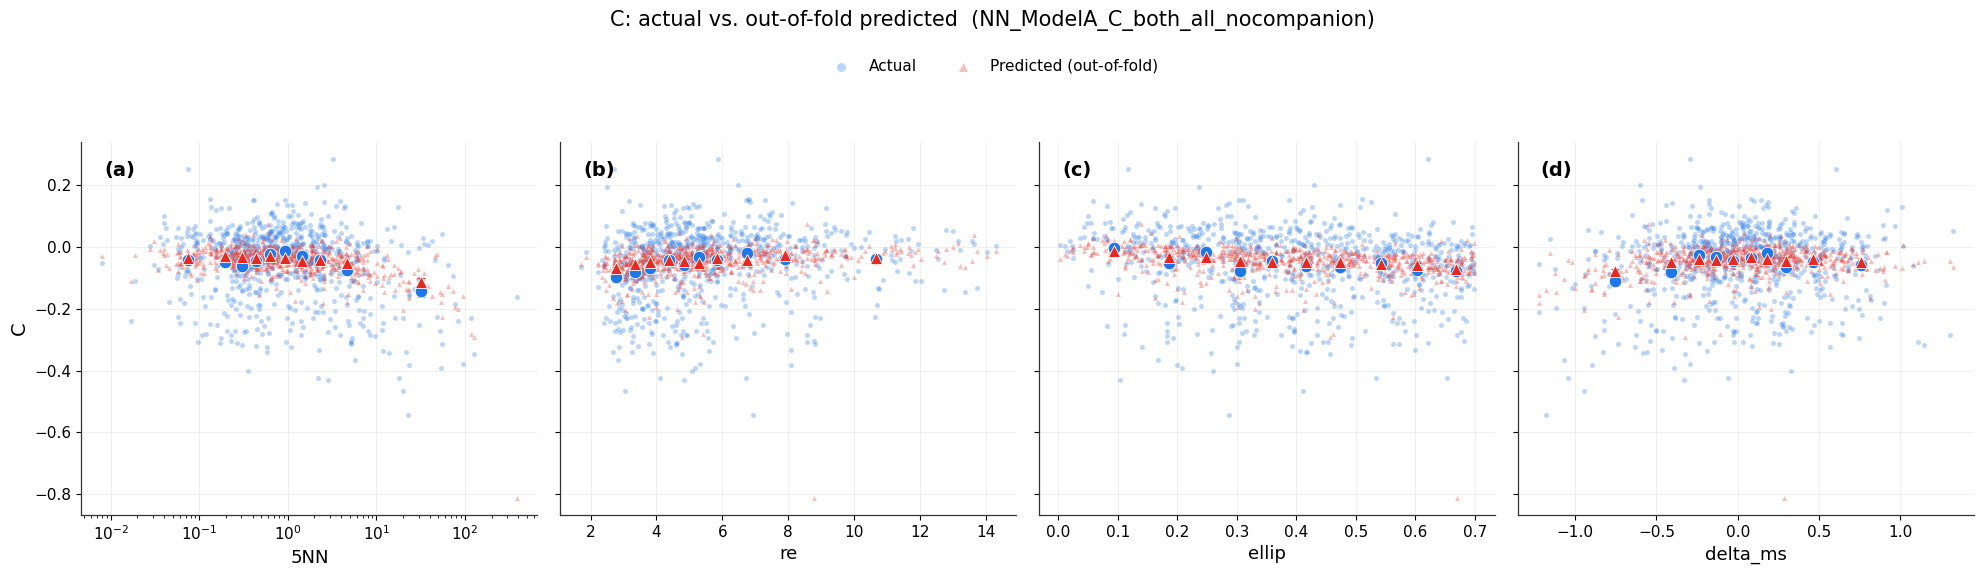

In [15]:
## ── Actual vs. Predicted vs. Feature (out-of-fold, full 5-fold CV) — thesis-ready ──

FEATURES_TO_PLOT = ['5NN', 're', 'ellip', 'delta_ms']
PANEL_LETTERS = ['(a)', '(b)', '(c)', '(d)']
N_BINS = 10

# Optional per-feature axis scale, e.g. {'5NN': 'log'} to spread out its dense,
# heavily right-skewed strip near zero (5NN spans ~0.01-100s within this sample).
X_SCALE = {'5NN': 'log'}

# Colourblind-safe, higher-contrast pair (Okabe–Ito)
CATEGORY_COLOURS = {
    'Actual':    '#1F77E8',  # deep blue
    'Predicted': '#E8291F',  # vermillion
}

assert len(FEATURES_TO_PLOT) == 4, "Pick exactly 4 features for the 1x4 row"
for f in FEATURES_TO_PLOT:
    assert f in df.columns, f"'{f}' not found in df — check spelling against FEATURES"

def binned_trend(x, y, n_bins=N_BINS):
    """Same binning approach as the Feature Relationship Explorer cell."""
    bin_edges = np.nanquantile(x, np.linspace(0, 1, n_bins + 1))
    bin_edges = np.unique(bin_edges)
    bin_idx = np.digitize(x, bin_edges[1:-1])
    bx, by, byerr = [], [], []
    for b in range(len(bin_edges) - 1):
        mask = bin_idx == b
        if mask.sum() < 3:
            continue
        bx.append(np.mean(x[mask]))
        by.append(np.mean(y[mask]))
        byerr.append(np.std(y[mask]) / np.sqrt(mask.sum()))
    return np.array(bx), np.array(by), np.array(byerr)

with plt.rc_context({
    'font.size': 12,
    'axes.labelsize': 13,
    'axes.titlesize': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#333333',
    'axes.linewidth': 0.9,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'grid.color': '#dddddd',
    'grid.linewidth': 0.6,
}):
    fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

    for i, (ax, feat) in enumerate(zip(axes, FEATURES_TO_PLOT)):
        x = df[feat].values

        # Scatter — small, low alpha, thin white edge to keep it crisp rather than muddy
        ax.scatter(x, oof_true, s=13, alpha=0.30, color=CATEGORY_COLOURS['Actual'],
                   edgecolors='white', linewidths=0.15, label='Actual', rasterized=True, zorder=2)
        ax.scatter(x, oof_pred, s=13, alpha=0.30, marker='^', color=CATEGORY_COLOURS['Predicted'],
                   edgecolors='white', linewidths=0.15, label='Predicted (out-of-fold)',
                   rasterized=True, zorder=2)

        # Binned trend lines — this is what actually sells the story
        bx, by_true, byerr_true = binned_trend(x, oof_true)
        bx, by_pred, byerr_pred = binned_trend(x, oof_pred)
        ax.errorbar(bx, by_true, yerr=byerr_true, fmt='o', color=CATEGORY_COLOURS['Actual'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6)
        ax.errorbar(bx, by_pred, yerr=byerr_pred, fmt='^', color=CATEGORY_COLOURS['Predicted'],
                    markersize=9, linewidth=1.8, capsize=3, zorder=4,
                    markeredgecolor='white', markeredgewidth=0.6)

        if feat in X_SCALE:
            ax.set_xscale(X_SCALE[feat])

        ax.text(0.05, 0.95, PANEL_LETTERS[i], transform=ax.transAxes,
                fontsize=14, fontweight='bold', va='top', ha='left')
        ax.set_xlabel(feat, fontsize=13)
        if i == 0:
            ax.set_ylabel(target, fontsize=14)
        ax.grid(alpha=0.5, zorder=0)

    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles[:2], labels[:2], loc='upper center', bbox_to_anchor=(0.5, 1.08),
               ncol=2, fontsize=11, frameon=False, markerscale=1.8)
    fig.suptitle(f'{target}: actual vs. out-of-fold predicted  ({RUN_LABEL})',
                 fontsize=15, y=1.15)
    plt.tight_layout()
    plt.show()